![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/05/logo-upv-horizontal.png)
![PIC UPV PERTE Chip Chair Logo](https://www.pic-chair.upv.es/wp-content/uploads/2024/06/logos-perte-chip-1024x119.png)


# Laboratory 1. Waveguides

Welcome to our Photonic Integrated Circuits Laboratory! Throughout the course, we will be using a Python package called [GDSFactory](https://gdsfactory.github.io/gdsfactory/index.html). This is an open-source tool, and is a great alternative to other commercial software like Synopsys Optodesigner, Luceda Photonics, or Lumerical/Interconnect. Since it runs on Python, you have two options for executing your laboratory tasks:

1. **Local installation on your own PC** (Recommended): Please note that we will not spend class time on installing the software. However, feel free to reach out if you need help with the installation.

2. **Cloud Workspace**: Alternatively, you can use a cloud-based solution if the Local installation does not work.

## 0. Imports

For this laboratory you will need the following libraries:

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import tidy3d as td

import gplugins as gp
import gplugins.tidy3d as gt
from gplugins import plot
from gplugins.common.config import PATH

nm = 1e-3
wavelength = np.linspace(1500, 1600,11) * nm
f = td.C_0 / wavelength

plt.style.use('seaborn-v0_8-dark')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.dpi': 150,
    'savefig.dpi': 200,
    'font.size': 13,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'legend.fontsize': 12,
    'lines.linewidth': 2,
    'lines.markersize': 6,
})


In [2]:
nitride_complex = td.material_library["Si3N4"]["Luke2015PMLStable"].eps_model(f)
nitride_index, nitride_k = td.Medium.eps_complex_to_nk(nitride_complex)
box_complex = td.material_library["SiO2"]["Horiba"].eps_model(f)
box_index, box_k = td.Medium.eps_complex_to_nk(box_complex)

## LO.1. Effective index of a waveguide

### Convergence Tests
We have asumed until now, that the **real** value of the effective index for each cross-section is the value provided by this mode-solver. However, this number relies on a numerical method, making it sensible to some input parameters, such as the selected grid. The objective of this section is to find the dependence of the **calculated** value of the effective index with the *grid_resolution* and the *max_grid_scaling*, the two parameters that we can modify from the automatic grid function used at the gt.modes.Waveguide() function.  <br>
- Consider a 1.2 um width deep waveguide (SiNx), with 0.3 um height operating at 1550 nm.
    - Sweep the *grid_resolution* between 10 and 100 in steps of 10. Plot the **calculated** effective index vs the *grid_resolution*. 
    - Select a value for the *grid_resolution* from the latter sweep (where the calculated index remains almost constant), and sweep the *max_grid_scaling* from 1.2 to 1.6 in steps of 0.1. Plot the **calculated** effective index vs the *max_grid_scaling*.
    - Conclude which will be the best configuration for the grid parameters for this particular case. 

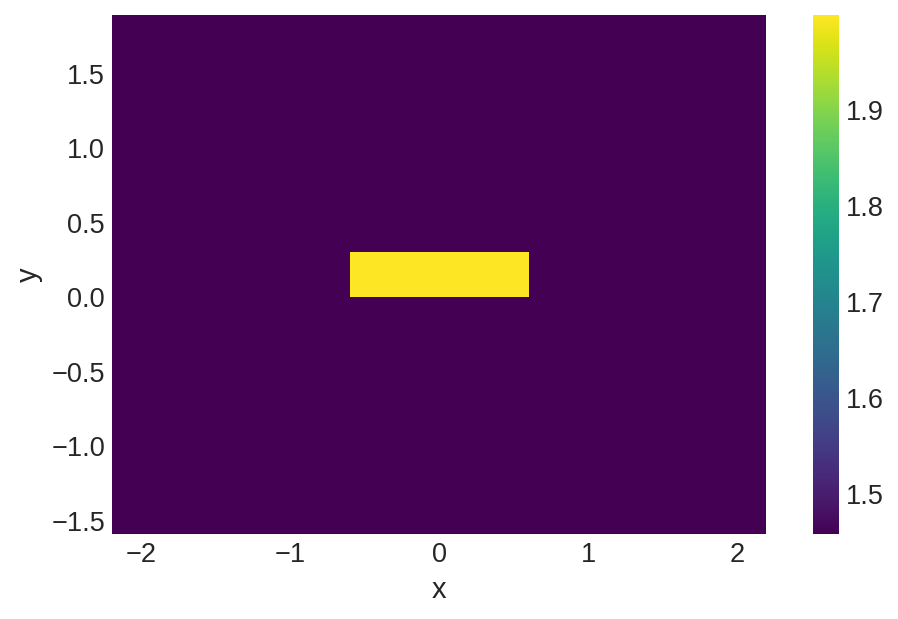

In [3]:
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

deep_waveguide.plot_index()

# Student continue your code here ...


In [4]:
deep_waveguide.n_eff

2026-11-09 19:18:34.900 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf92515ae4232c65.npz.


array([1.60524792+0.00010066j, 1.52829803+0.00017753j,
       1.45072999+0.00019228j, 1.43325817+0.00021838j])

# From 10 to 100 step 10 Resolution

In [5]:
def get_TF00(gridres):
    deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=gridres, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    )
    return deep_waveguide.n_eff[0]
tf00 = []
for i in range(10,110,10):
    tf00.append(get_TF00(i))
print(tf00)

2026-11-09 19:18:36.365 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_13fe960528db7e9b.npz.
2026-11-09 19:18:36.376 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf92515ae4232c65.npz.
2026-11-09 19:18:36.380 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_152975b7cd7bd92b.npz.
2026-11-09 19:18:36.382 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_721700b7522a7617.npz.
2026-11-09 19:18:36.383 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_0ea6c3bb3b1c00e8.npz.
2026-11-09 19:18:36.385 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_67a04e2475ce3436.npz.
2026-11-09 19:18:36.386 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_b110164ae7f9a70a.npz.
2026-11-09 19:18:36.388 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_c8d8b6bf9be8a3e8.npz.


[10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
[np.float64(1.6292176135816767), np.float64(1.6052479180535963), np.float64(1.6140019734701279), np.float64(1.61159935779143), np.float64(1.6053589955147283), np.float64(1.6053793907406797), np.float64(1.6053907755111803), np.float64(1.6052625161349372), np.float64(1.6054075206236817), np.float64(1.605413030422194)]


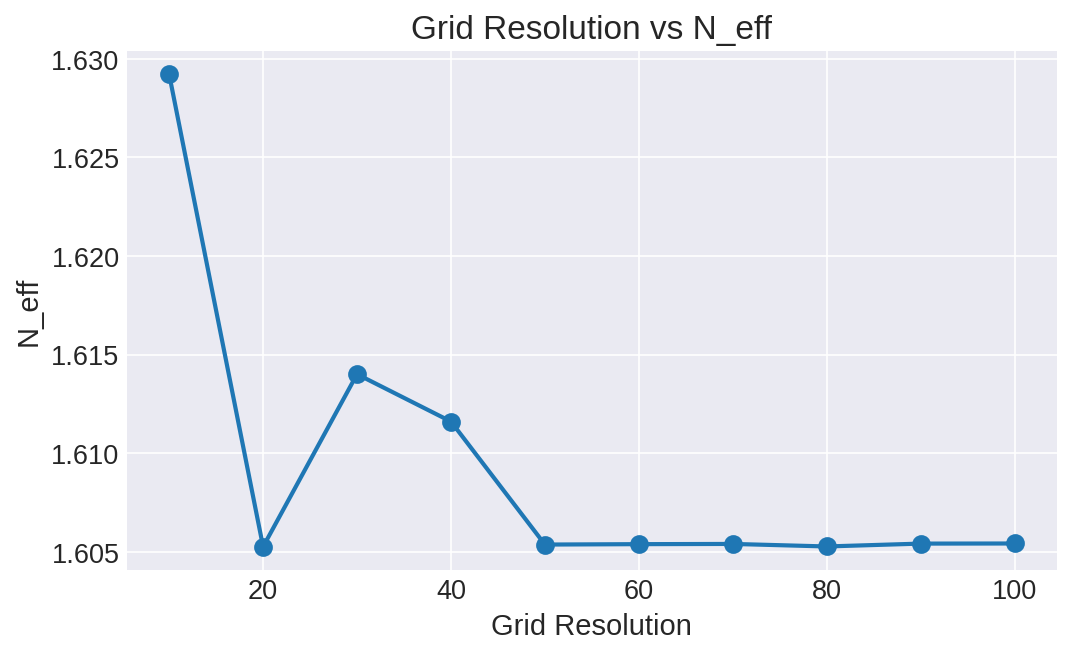

In [6]:
#plot
gridres=[i for i in range(10,110,10)]
realneff = [i.real for i in tf00]
print(gridres)
print(realneff)
#plt.plot(x, y, marker='o', linestyle='-', markersize=4)
plt.style.use('seaborn-v0_8-dark')
plt.plot(gridres, realneff, marker='o', linestyle='-', markersize=8)
plt.xlabel('Grid Resolution')
plt.ylabel('N_eff')
plt.title('Grid Resolution vs N_eff')
plt.grid(True)
plt.show()

# Max grid scaling plot

In [7]:
last_grid_res = gridres[-1]
# 1.2 to 1.6 in 0.1
max_grid_scal = np.arange(1.2, 1.7, 0.1)
print(max_grid_scal)

def get_max_grid_scale(gridres, max_grid_scale):
    deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=1.2, # Waveguide width
    core_thickness=300 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='sin', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=max_grid_scale, # Parameters of the grid 
    grid_resolution=gridres, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    )
    return deep_waveguide.n_eff[0]
tf00_maxgrid_scale = []
for i in max_grid_scal:
    tf00_maxgrid_scale.append(get_max_grid_scale(last_grid_res, i))
print(tf00_maxgrid_scale)

[1.2 1.3 1.4 1.5 1.6]
2026-11-09 19:18:42.195 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf88991cd1d9b5bd.npz.
2026-11-09 19:18:42.210 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_ad057520998c64f0.npz.
2026-11-09 19:18:42.212 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_51a69e9dd16755ee.npz.
2026-11-09 19:18:42.214 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_aad70ff6baab3ead.npz.
2026-11-09 19:18:42.216 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_d6ab87fc220a3984.npz.
[np.complex128(1.6079424675958947+9.914139236708413e-05j), np.complex128(1.605525127229275+0.00010036932184823146j), np.complex128(1.6055233270578015+0.00010037187528018864j), np.complex128(1.605413030422194+0.00010048234928533234j), np.complex128(1.6054127798343036+0.00010048271754363607j)]


[1.2 1.3 1.4 1.5 1.6]
[np.float64(1.6079424675958947), np.float64(1.605525127229275), np.float64(1.6055233270578015), np.float64(1.605413030422194), np.float64(1.6054127798343036)]


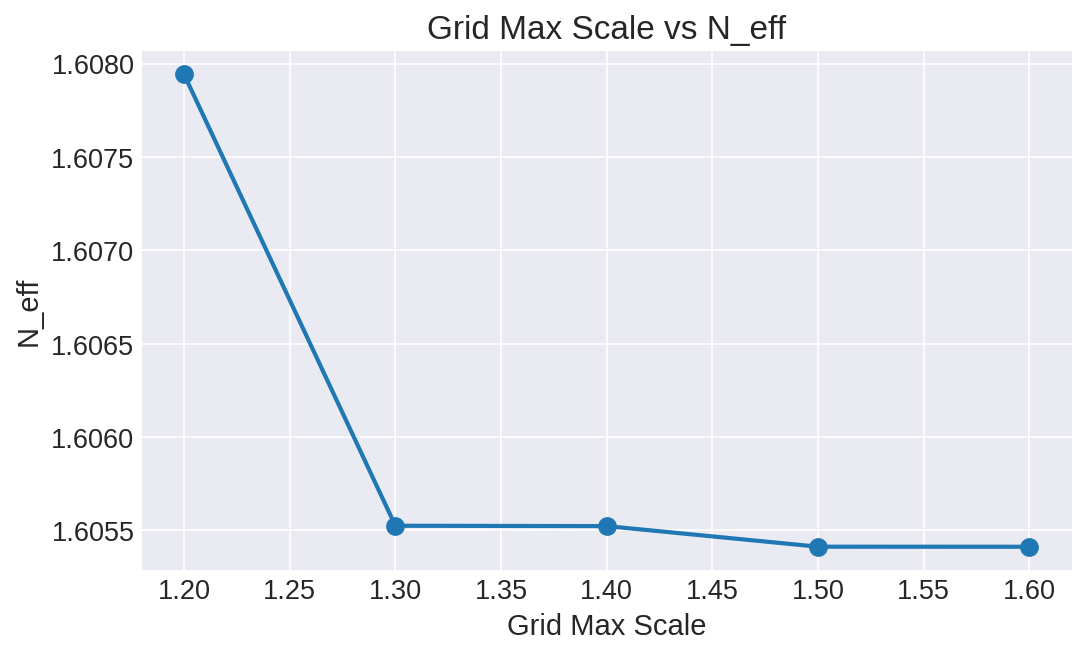

In [8]:
#plot
x=max_grid_scal
y =  [i.real for i in tf00_maxgrid_scale]
print(x)
print(y)
plt.plot(x, y,marker='o', linestyle='-', markersize=8)
plt.xlabel('Grid Max Scale')
plt.ylabel('N_eff')
plt.title('Grid Max Scale vs N_eff')
#plt.hlines(np.mean(box_index), xmin=np.min(x), xmax=np.max(x), colors='k', linestyles='dashed',label='SiO2 index')

plt.grid(True)
plt.show()

## LO.2. Width dependence

- Perform a sweep of the **deep** waveguide width. Use the code provided in the following cell or program your own sweep. 

  0%|          | 0/10 [00:00<?, ?it/s]

2026-11-09 19:18:47.383 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e0f2a62752cad497.npz.
2026-11-09 19:18:47.396 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cad20f99025f789a.npz.
2026-11-09 19:18:47.397 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_ccd09e642d54ed9e.npz.
2026-11-09 19:18:47.400 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bd0ebb0b8e1dda50.npz.
2026-11-09 19:18:47.401 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_d4c0f75aabdd9690.npz.
2026-11-09 19:18:47.402 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_65a4004dca43601c.npz.
2026-11-09 19:18:47.404 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bcaefffe13a550c8.npz.
2026-11-09 19:18:47.405 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_dc90d742fae9dc78.npz.


  0%|          | 0/10 [00:00<?, ?it/s]

2026-11-09 19:18:47.415 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e0f2a62752cad497.npz.
2026-11-09 19:18:47.417 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cad20f99025f789a.npz.
2026-11-09 19:18:47.418 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_ccd09e642d54ed9e.npz.
2026-11-09 19:18:47.419 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bd0ebb0b8e1dda50.npz.
2026-11-09 19:18:47.420 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_d4c0f75aabdd9690.npz.
2026-11-09 19:18:47.421 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_65a4004dca43601c.npz.
2026-11-09 19:18:47.422 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bcaefffe13a550c8.npz.
2026-11-09 19:18:47.423 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_dc90d742fae9dc78.npz.


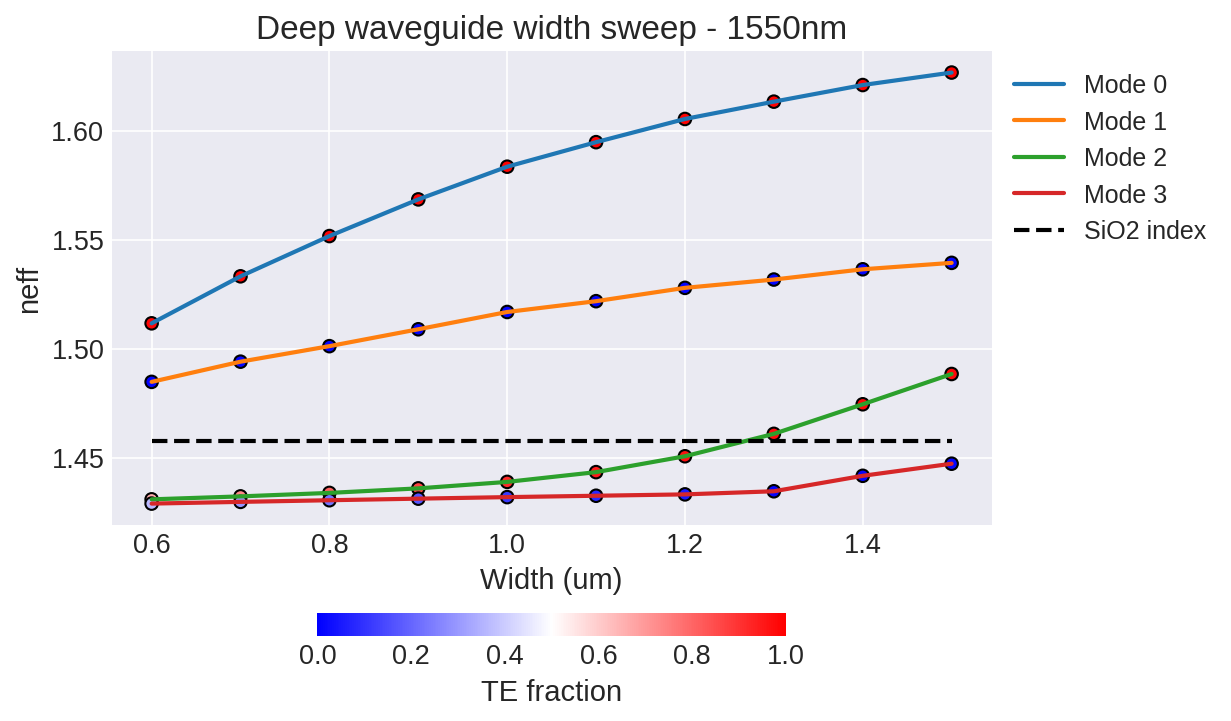

In [9]:
wavelength = 1550 * nm # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=1.2,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)

w = np.arange(0.6, 1.6, 0.1)

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (um)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

## LO.3. Waveguide compact model

A compact model of an integrated photonic waveguide is a reduced-order mathematical model that describes the waveguide’s optical behavior—such as phase propagation, loss, and dispersion, using analytical or semi-analytical equations. Consider: 

Transfer function for propagation in a waveguide:

$$
H(\lambda)
= e^{-j\,\beta(\lambda)\,z}
= e^{-j\,\mathrm{Re}\{\beta(\lambda)\}\,z}\,
  e^{\mathrm{Im}\{\beta(\lambda)\}\,z}.
$$

Where 

$$
\beta(\lambda)
= \frac{2\pi}{\lambda}\,\mathrm{Re}\{n_\mathrm{eff}(\lambda)\}.
$$

Let's model the waveguide's effective index wavelength variation using a second order polynomial:

$$
n_\mathrm{eff}(\lambda)
= n_{1} + n_{2}\,(\lambda-\lambda_{0}) + n_{3}\,(\lambda-\lambda_{0})^{2}
$$

Where 

1. 
$$
n_\mathrm{eff}(\lambda_0) = n_1
$$
2. 
$$
n_g(\lambda_0) = n_1 - n_2\,\lambda_0
$$
3. 
$$
D = -\frac{2\,\lambda_0\,n_3}{c}\;\;[\mathrm{s}^2/\mathrm{m}]
$$

- Find the **compact models** of the following waveguides: 
    - Deep waveguide, height = 300nm, width = 1.2um 
    - Shallow waveguide, core height = 300nm, slab height = 150 nm, width = 1.2um 

**TIP**. Use the Lab0.1.Modesolver results (neff vs lambda) as starting point. Fit the results using a second order polynomial (with the lambda_0 shift) and relate the fit results to n_g and D values.

2026-11-09 20:04:49.943 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e70065e5b5dc42c3.npz.


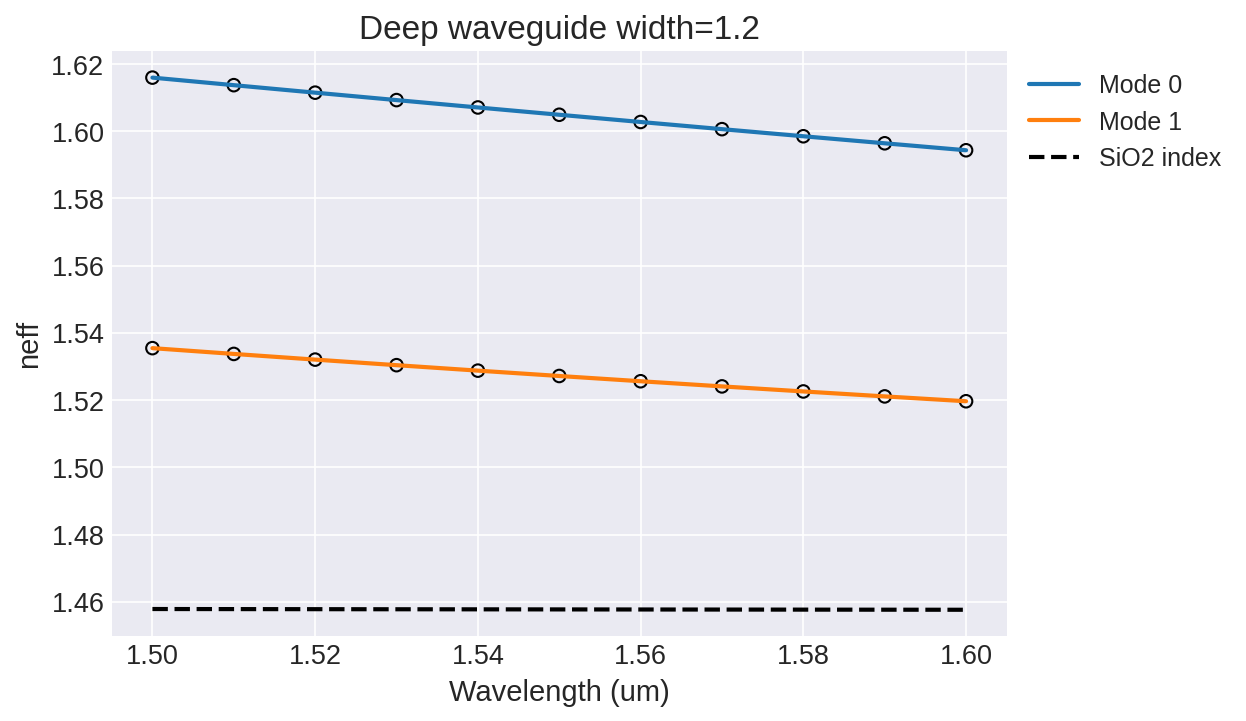

In [40]:
# STUDENT! Put your code here.

# The wavelength could be a vector also
#DEEP WG
wavelength = np.linspace(1.5,1.6,11)  # Student code here. Tip np.linspace()

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=1.2, 
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in [0, 1]:
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])


#Data to fit for mode0
wavelength_dif = wavelength-1.55
neff0 = res_neff[:,0]

#Data to fit for mode1
neff1 = res_neff[:,1]


Mode 0 n1=1.604916629102674, n2=-0.21617694948864513, n3=0.09735506571599926
Mode 1 n1=1.5271892343288163, n2=-0.1579587829277265, n3=0.15383171323761552


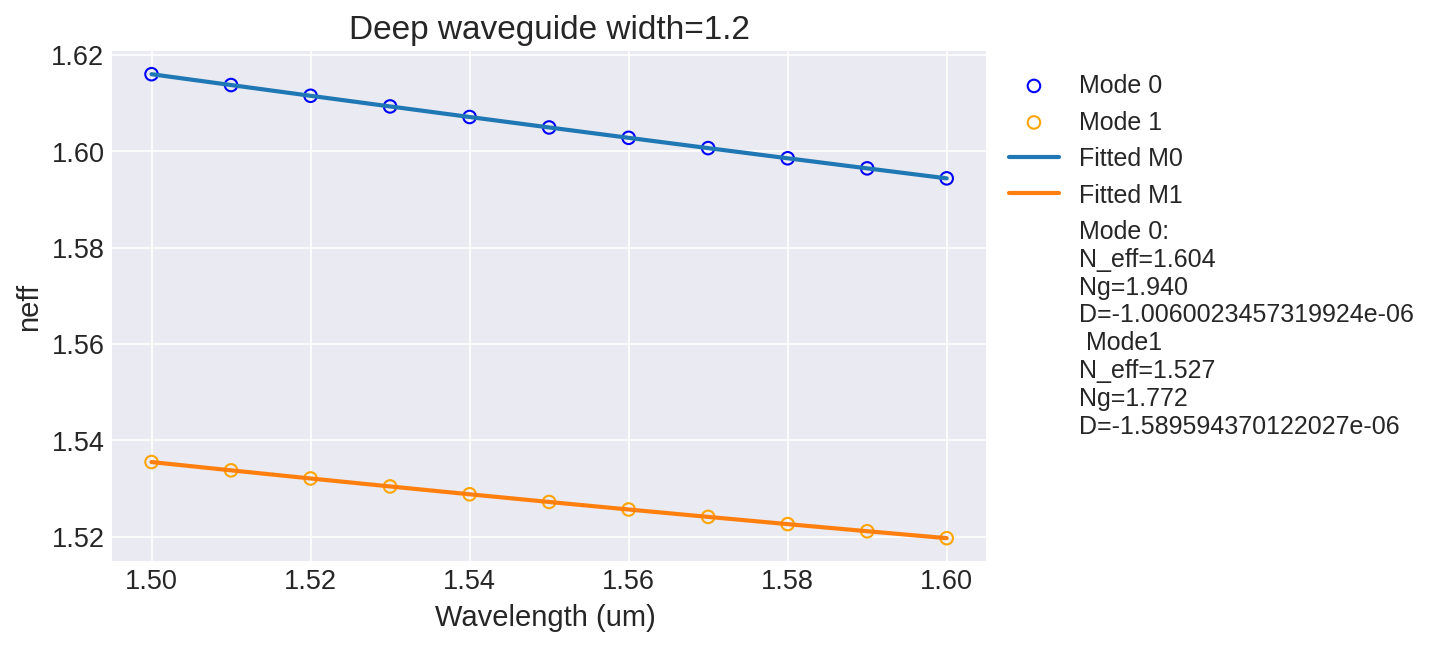

In [41]:
from matplotlib.lines import Line2D
lambda0 = 1.55
cmeter = 3*(10**17)
pte = np.polyfit(wavelength_dif, neff0.real, 2)
pm = np.polyfit(wavelength_dif, neff1.real, 2)
print (f"Mode 0 n1={pte[-1]}, n2={pte[1]}, n3={pte[0]}")
print (f"Mode 1 n1={pm[-1]}, n2={pm[1]}, n3={pm[0]}")
#Mode 0
neff0_fit = np.polyval(pte, wavelength_dif)
neff1_fit = np.polyval(pm, wavelength_dif)
n1 = pte[-1]
ng = pte[-1] - pte[1]*1.55
D = -(2*lambda0*pte[0])*((10**12)) / cmeter
#Mode 1
neff1_fit = np.polyval(pm, wavelength_dif)
Mod1_1n1 = pm[-1]
Mod1_1ng = pm[-1] - pm[1]*1.55
Mod1_D = -(2*lambda0*pm[0])*((10**12)) /cmeter

plt.scatter(wavelength, neff0.real,edgecolors='blue',facecolors='none',label = 'Mode 0')
plt.scatter(wavelength, neff1.real,edgecolors='orange',facecolors='none',label = 'Mode 1')

plt.plot(wavelength, neff0_fit, label="Fitted M0")
plt.plot(wavelength, neff1_fit, label="Fitted M1")

plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (um) ")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.ylabel("neff")
plt.grid()
handles, labels = plt.gca().get_legend_handles_labels()
datamode0 = f"N_eff={str(pte[-1])[0:5]} \nNg={ng:.3f} \nD={D}\n"
datamode1 = f"N_eff={str(Mod1_1n1)[0:5]} \nNg={Mod1_1ng:.3f} \nD={Mod1_D}\n"

handles.append(Line2D([], [], linestyle='none', label="Mode 0: \n" +datamode0+" Mode1\n"+datamode1))

plt.legend(handles=handles, loc='upper left', bbox_to_anchor=(1, 1))



# Shallow WG

2026-11-09 20:05:00.033 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_cf0af488213d9e23.npz.
Mode 0 n1=1.6240906297465496, n2=-0.18817489158079223, n3=0.09569580270911887
Mode 1 n1=1.5418953646135445, n2=-0.13259849406326255, n3=0.14801175111752993


<Figure size 1200x675 with 0 Axes>

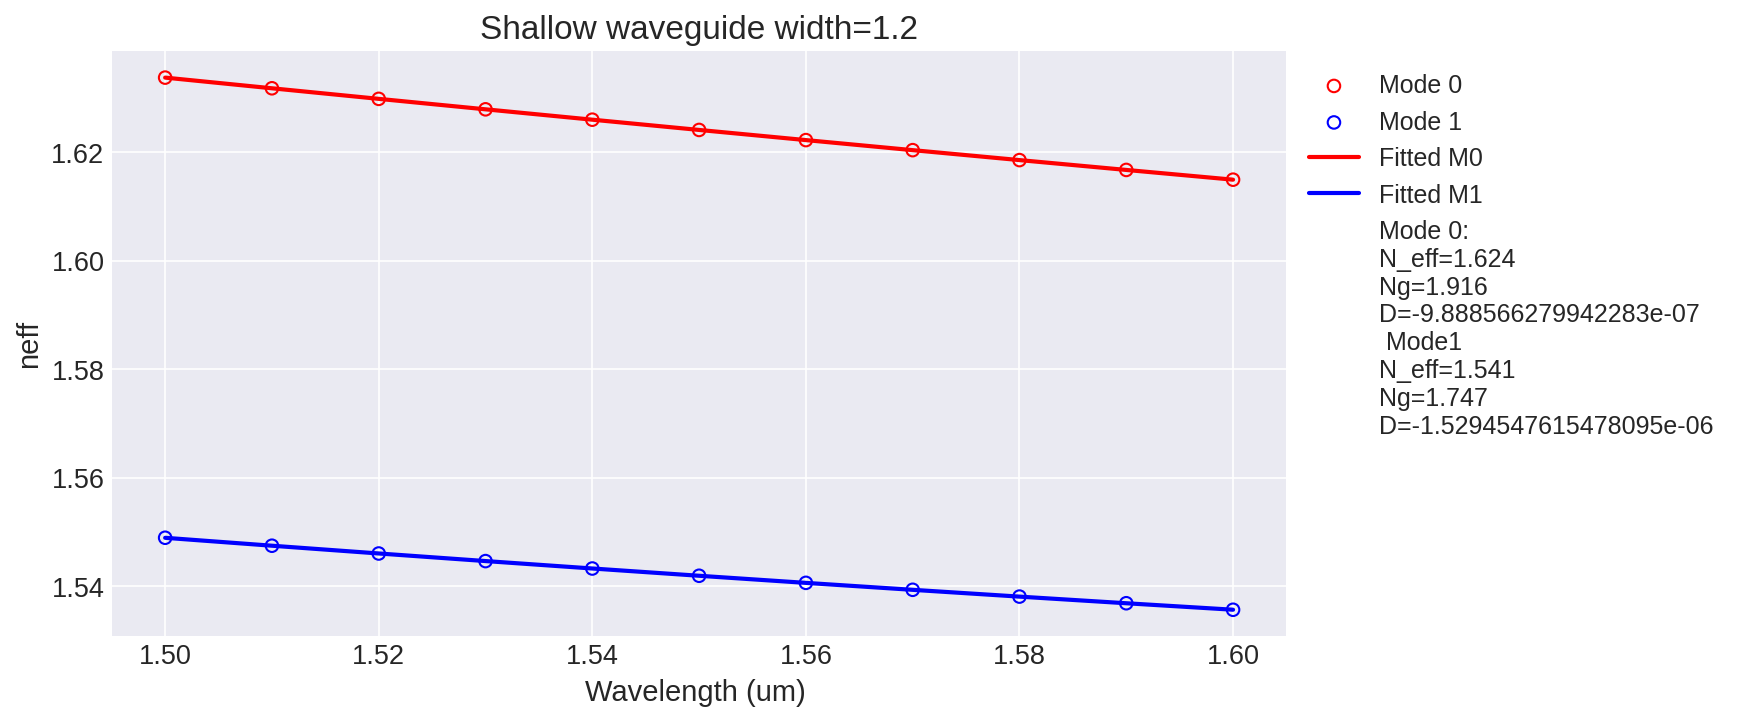

In [42]:
# STUDENT! Put your code here.
plt.clf()
wavelength = np.linspace(1.5,1.6,11)  # Student code here. Tip np.linspace()
shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=1.2, 
    slab_thickness=150*nm,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=20, 
)

res_neff = shallow_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = shallow_waveguide.fraction_te # Wavelength-dependent vector
res_tm =shallow_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))



#Data to fit for mode0
wavelength_dif = wavelength-1.55
neff0 = res_neff[:,0]

#Data to fit for mode1
neff1 = res_neff[:,1]

p = np.polyfit(wavelength_dif, neff0.real, 2)
p1 = np.polyfit(wavelength_dif, neff1.real, 2)
print (f"Mode 0 n1={p[-1]}, n2={p[1]}, n3={p[0]}")
print (f"Mode 1 n1={p1[-1]}, n2={p1[1]}, n3={p1[0]}")
#Mode 0
neff0_fit = np.polyval(p, wavelength_dif)
neff1_fit = np.polyval(p1, wavelength_dif)
n1 = p[-1]
ng = p[-1] - p[1]*1.55
D = -(2*lambda0*p[0]) *((10**12))/ cmeter
#Mode 1
neff1_fit = np.polyval(p1, wavelength_dif)
Mod1_1n1 = p1[-1]
Mod1_1ng = p1[-1] - p1[1]*1.55
Mod1_D = -(2*lambda0*p1[0])*((10**12)) / cmeter

plt.scatter(wavelength, neff0.real,edgecolors='red',facecolors='none',label = 'Mode 0', color= "red",)
plt.scatter(wavelength, neff1.real,edgecolors='blue',facecolors='none',label = 'Mode 1', color= "blue")

plt.plot(wavelength, neff0_fit, label="Fitted M0", color= "red")
plt.plot(wavelength, neff1_fit, label="Fitted M1", color= "blue")

plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (um) ")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.ylabel("neff")
plt.grid()
handles, labels = plt.gca().get_legend_handles_labels()
datamode0 = f"N_eff={str(p[-1])[0:5]} \nNg={ng:.3f} \nD={D}\n"
datamode1 = f"N_eff={str(Mod1_1n1)[0:5]} \nNg={Mod1_1ng:.3f} \nD={Mod1_D}\n"

handles.append(Line2D([], [], linestyle='none', label="Mode 0: \n" +datamode0+" Mode1\n"+datamode1))

plt.legend(handles=handles, loc='upper left', bbox_to_anchor=(1, 1))

## LO.4. Bend waveguide radius vs. loss – deep

The bend loss has three primary contributions:

1. Mode-mismatch loss
2. Radiation loss
3. Propagation loss

2026-11-09 04:29:47.007 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_36b1d7eb6dcc2b2e.npz.


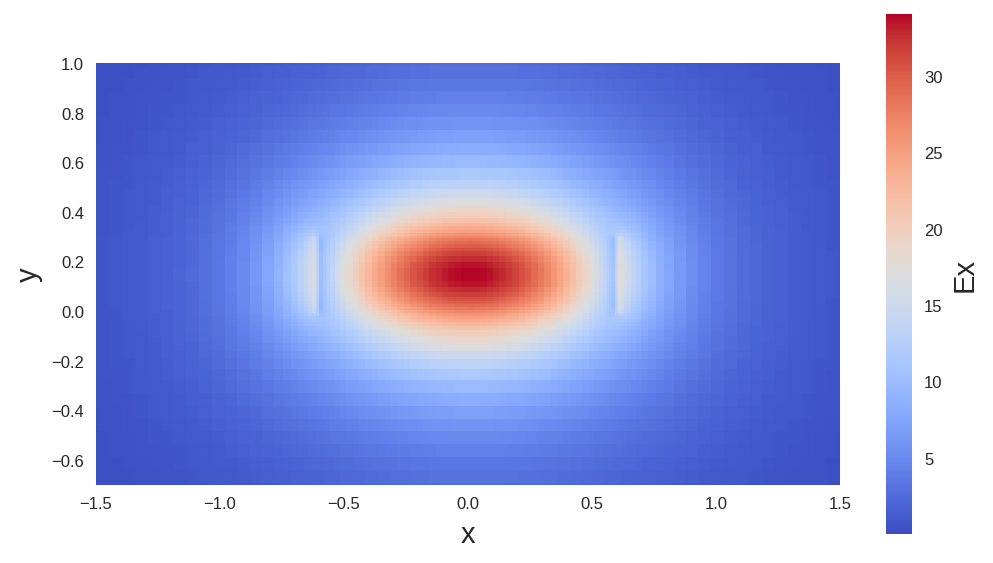

In [51]:
bend_1550 = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=1.2,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=1,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    
    grid_resolution=30, 
    bend_radius=200, # Bend radius
)

bend_1550.plot_field(field_name="Ex", 
                     mode_index=0, # Field to be plotted
                     value='abs', # Real - abs - imag
                     cmap='coolwarm',
                     xlim=(-1.5, 1.5), # Set the x and y limits
                     ylim=(-0.7, 1)) 

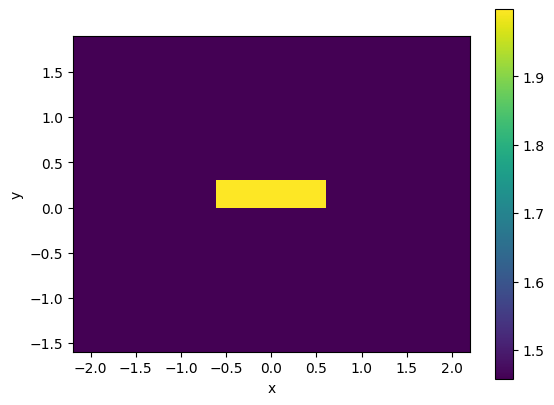

In [96]:
bend_1550.plot_index()

### Mode-mismatch loss

Bend waveguide mode differs slightly from the straight waveguide mode, wich yield into mode-convertion losses. We can calculate this factor with as the overlap of the latter two modes. 

This is already implemented on GDSfactory library: 

  0%|          | 0/6 [00:00<?, ?it/s]

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

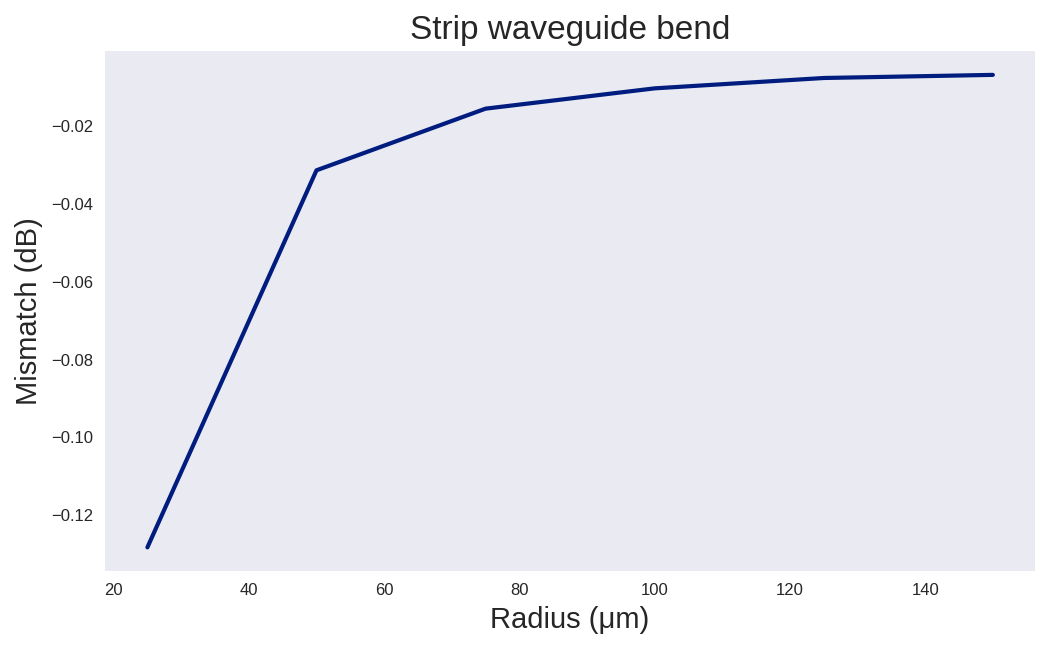

In [66]:
radii = np.arange(25.0, 175,25)

mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)
plt.clf()
plt.plot(radii, 10 * np.log10(mismatch))
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.show()

### Propagation loss

Consider the equivalent linear length of the quarter-circle bend. Light will attenuate following a trend quantified with the experimentally measured parameter $$\alpha [\mathrm{dB}/\mathrm{cm}]$$. It depends on the fabrication process mainly. We will add this loss (in dBs) to the mode-mismatch loss to calculate the total loss per bend. 

*We are not considering the radiation losses, mainly because is not easy to implement a quick simulation for this parameter. Under certain conditions, the main loss sources are the ones considered in this example


Text(0, 0.5, 'Mismatch (dB)')

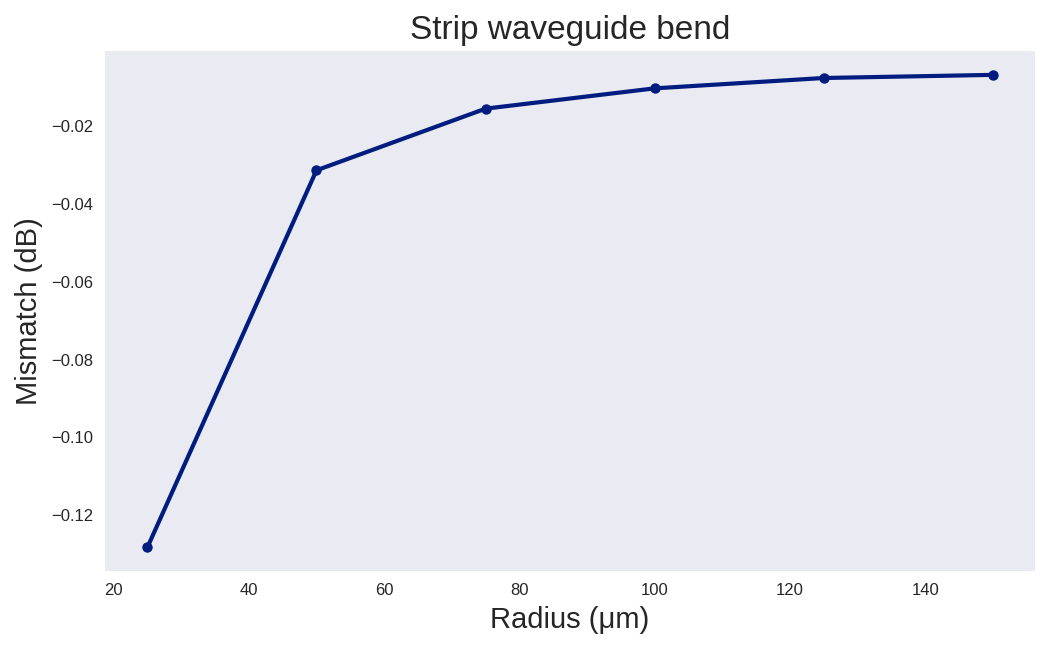

In [67]:
plt.clf()
plt.plot(radii, 10 * np.log10(mismatch),marker='o', linestyle='-', markersize=5)
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")


  0%|          | 0/6 [00:00<?, ?it/s]

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

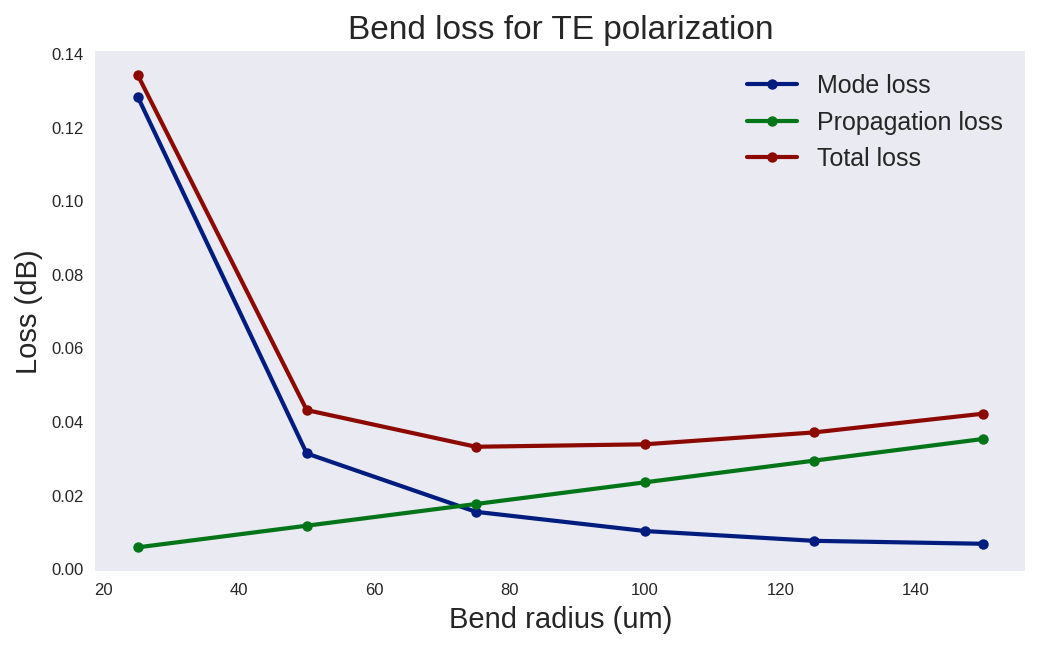

In [68]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss = dB_cm * length * 1e2
propagation_loss
mismatch = gt.modes.sweep_bend_mismatch(bend_1550, radii)
plt.clf()
plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch), ".", label="Mode loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss, ".", label="Propagation loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss-10 * np.log10(mismatch), ".", label="Total loss",marker='o', linestyle='-', markersize=5)
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()

- Use the code provided in this section to calculate the safe radius for 1.2 um width deep waveguides at 1.5 um. 

  0%|          | 0/6 [00:00<?, ?it/s]

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

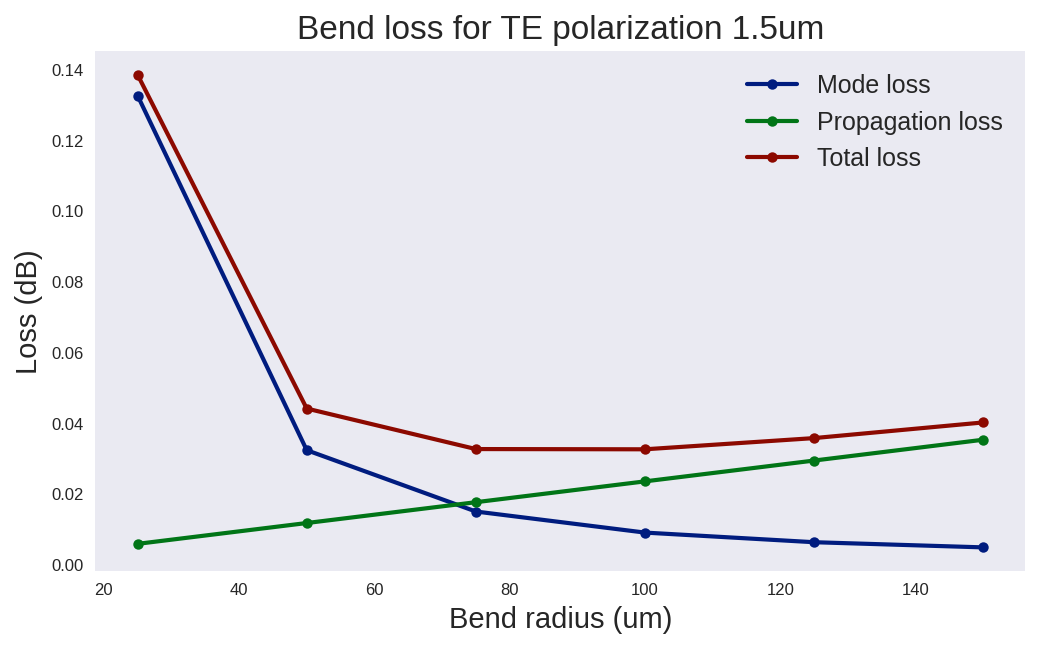

In [ ]:
bend_1500 = gt.modes.Waveguide(
    wavelength=1500 * nm,
    core_width=1.2,
    slab_thickness=0.0,
    core_material='sin',
    clad_material='sio2',
    core_thickness=300 * nm,
    num_modes=1,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=30, 
    bend_radius=200, # Bend radius
    )
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss_1500 = dB_cm * length * 1e2
propagation_loss_1500
mismatch_1500 = gt.modes.sweep_bend_mismatch(bend_1500, radii)
plt.clf()
plt.title("Bend loss for TE polarization 1.5um")
plt.plot(radii, -10 * np.log10(mismatch_1500), ".", label="Mode loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss, ".", label="Propagation loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_1500), ".", label="Total loss",marker='o', linestyle='-', markersize=5)
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()

# Safe radio starts at around 40um

# PPT slide 6


In [119]:
def waveguide_customRadio(radio):
    bend_1550_ppt = gt.modes.Waveguide(
        wavelength=1550 * nm,
        core_width=1,
        slab_thickness=0.0,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=2,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20, 
        bend_radius=radio, # Bend radius
        )
    print (bend_1550_ppt.fraction_te[0], bend_1550_ppt.fraction_tm[1]) # to verify first two modes are te and tm
    return bend_1550_ppt



In [115]:
radii = np.arange(25.0, 175,25)
for i in radii:
    waveguide_customRadio(i)
bend_1550 = gt.modes.Waveguide(
        wavelength=1550 * nm,
        core_width=1,
        slab_thickness=0.0,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=2,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20, 
        bend_radius=200, # Bend radius
        )
mismatch_te_tm = gt.modes.sweep_bend_mismatch(bend_1550, radii)



2026-11-09 05:18:46.501 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_1fae764bf0767424.npz.
0.9930815905050163 0.00039564268052290244
2026-11-09 05:18:46.503 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_b9bdbd79392dcce5.npz.
0.993324324971202 0.9897213043396258
2026-11-09 05:18:46.504 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_08a772776e70889d.npz.
0.9933722573409497 0.989586683147159
2026-11-09 05:18:46.505 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_779c02d389de4a38.npz.
0.993390014677859 0.9895434446543294
2026-11-09 05:18:46.507 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_2ff7e8d79f403ed2.npz.
0.9933986858741354 0.9895244556702713
2026-11-09 05:18:46.509 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_deb6ae3ef82f087f.npz.
0.9934036410492385 0.9895144804949692


  0%|          | 0/6 [00:00<?, ?it/s]

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

05:18:47 CET WARNING: Mode field at frequency index 0, mode index 1 does not    
             decay at the plane boundaries.                                     

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

Text(0, 0.5, 'Mismatch (dB)')

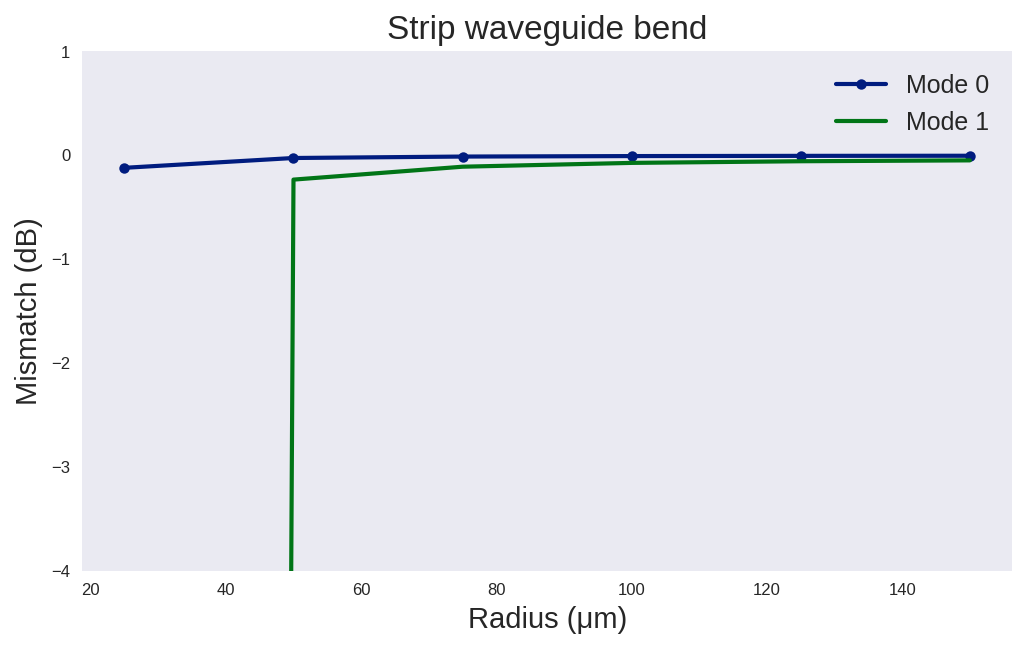

In [ ]:
plt.plot(radii, 10 * np.log10(mismatch_te_tm.T[0]), label="Mode 0",marker='o', linestyle='-', markersize=5)
plt.plot(radii, 10 * np.log10(mismatch_te_tm.T[1]), label="Mode 1")
plt.ylim(-4,1)
plt.legend()
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")

2026-11-09 05:38:24.727 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_2922e6cadd11eaac.npz.
0.992691331790624---0.0006364119230580765
2026-11-09 05:38:24.729 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_c68b5218b350a284.npz.
0.9929749507267692---0.9896572604142755
2026-11-09 05:38:24.732 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_fb718f94a4088a90.npz.
0.9930360192124681---0.989503739423389
2026-11-09 05:38:24.733 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_ad15739e63731d6c.npz.
0.9930601021734169---0.9894559860507244
2026-11-09 05:38:24.735 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_4844a479b5c35d35.npz.
0.9930724823199053---0.9894352222174883
2026-11-09 05:38:24.736 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_1e330f5394fc6dd5.npz.
0.9930798781029049---0.9894243726539835


/tmp/ipykernel_231966/3397096776.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0, 0.5, 'N_eff ')

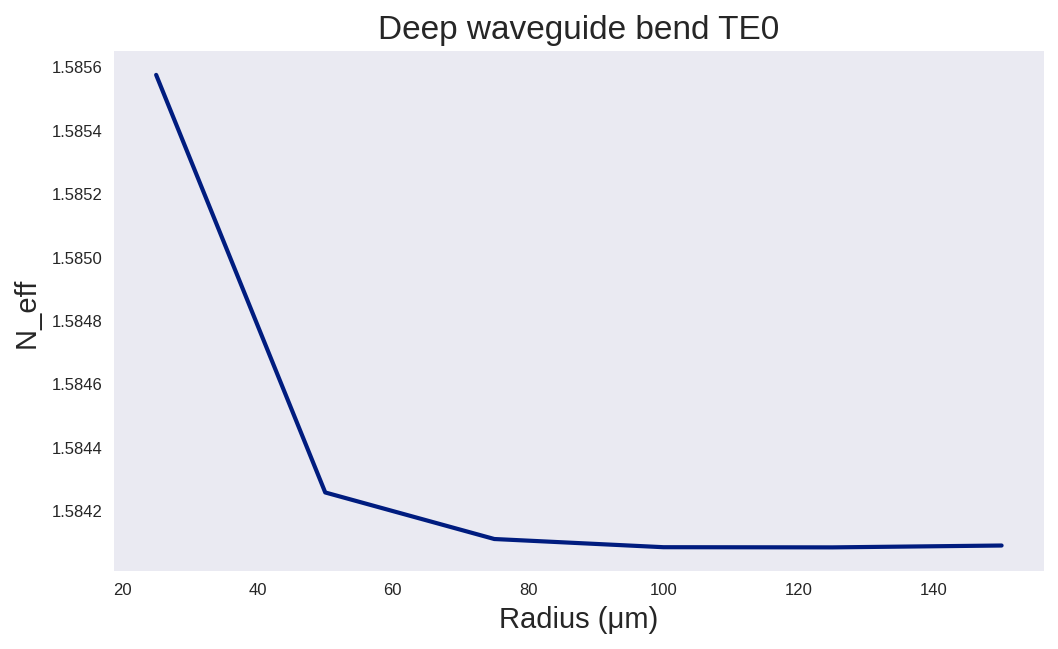

In [133]:
# find radiys vsneff
TEdata = []
TMdata = []
neff = []
for i in radii:
    bend_1550_for = gt.modes.Waveguide(
        wavelength=1550 * nm,
        core_width=1.,
        slab_thickness=0.0,
        core_material='sin',
        clad_material='sio2',
        core_thickness=300 * nm,
        num_modes=5,
        cache_path='.cache/',
        precision='double',
        max_grid_scaling=1.2,
        grid_resolution=20, 
        bend_radius=i, # Bend radius
        )
    neff.append(bend_1550_for.n_eff[0])
    TEdata.append(bend_1550_for.n_eff[0].real)
    TMdata.append(bend_1550_for.n_eff[1].real)
    print(str(bend_1550_for.fraction_te[0].real) +"---"+str(bend_1550_for.fraction_tm[1].real))
plt.plot(radii, TEdata)
plt.legend()
plt.title("Deep waveguide bend TE0")
plt.xlabel("Radius (μm)")
plt.ylabel("N_eff ")
    


/tmp/ipykernel_231966/553842380.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0, 0.5, 'N_eff ')

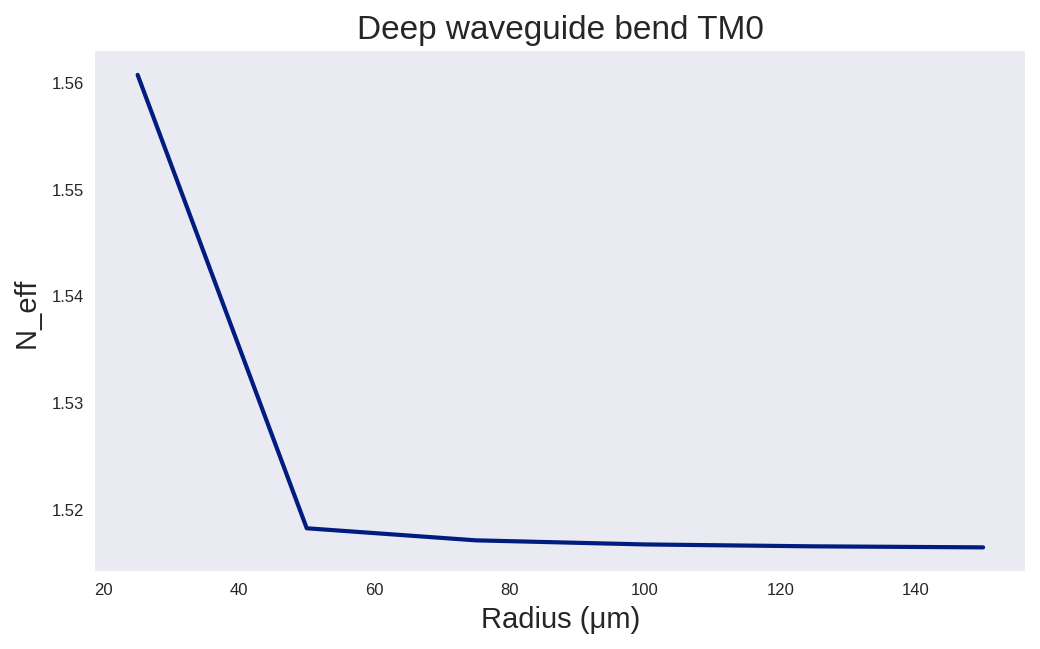

In [135]:
plt.plot(radii, TMdata)
plt.legend()
plt.title("Deep waveguide bend TM0")
plt.xlabel("Radius (μm)")
plt.ylabel("N_eff ")
    

/tmp/ipykernel_231966/2677576993.py:7: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, -10 * np.log10(mismatch_te_tm.T[0]), ".", label="Mode loss", marker='o', linestyle='-', markersize=5)
/tmp/ipykernel_231966/2677576993.py:8: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, propagation_loss, ".", label="Propagation loss",marker='o', linestyle='-', markersize=5)
/tmp/ipykernel_231966/2677576993.py:9: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, propagation_loss-10 * np.log10(mismatch_te_tm.T[0]), ".", label="Total loss",marker='o', linestyle='-', markersize=5)


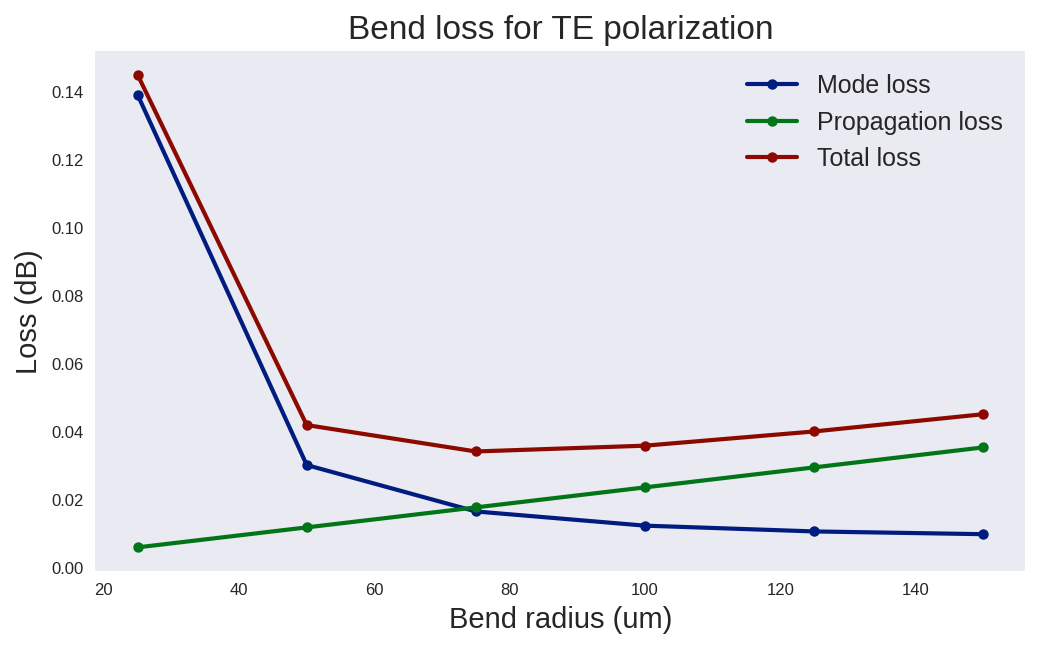

In [117]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss = dB_cm * length * 1e2
propagation_loss

plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch_te_tm.T[0]), ".", label="Mode loss", marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss, ".", label="Propagation loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_te_tm.T[0]), ".", label="Total loss",marker='o', linestyle='-', markersize=5)
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()

In [205]:
radii

array([ 25.,  50.,  75., 100., 125., 150.])

/tmp/ipykernel_231966/702569848.py:8: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, -10 * np.log10(mismatch_te_tm.T[1]), ".", label="Mode loss",marker='o', linestyle='-', markersize=5)
/tmp/ipykernel_231966/702569848.py:9: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, propagation_loss, ".", label="Propagation loss",marker='o', linestyle='-', markersize=5)
/tmp/ipykernel_231966/702569848.py:10: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, propagation_loss-10 * np.log10(mismatch_te_tm.T[1]), ".", label="Total loss",marker='o', linestyle='-', markersize=5)


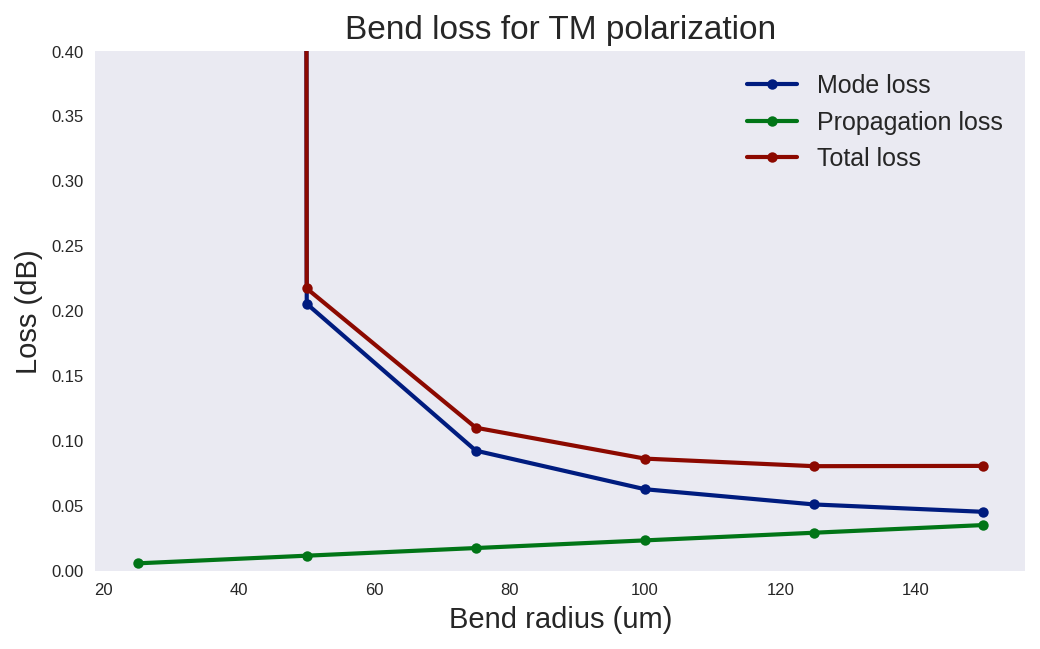

In [118]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss = dB_cm * length * 1e2
propagation_loss
plt.clf()
plt.ylim(top=.4)
plt.title("Bend loss for TM polarization")
plt.plot(radii, -10 * np.log10(mismatch_te_tm.T[1]), ".", label="Mode loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss, ".", label="Propagation loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_te_tm.T[1]), ".", label="Total loss",marker='o', linestyle='-', markersize=5)
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()


In [267]:
(propagation_loss-10 * np.log10(mismatch_te_tm.T[1]))[2:]

array([0.12831666, 0.09750002, 0.0875355 , 0.08507132])

In [203]:
mismatch_te_tm.T

array([[9.72428917e-01, 9.93828432e-01, 9.96997437e-01, 9.98058157e-01,
        9.98533361e-01, 9.98783938e-01],
       [1.23326722e-28, 9.47371248e-01, 9.74844801e-01, 9.83119234e-01,
        9.86714915e-01, 9.88614918e-01]])

## EXTRA

All the past simulations were done considering as core material de Silicon Nitride (SiNx) and Silicon Dioxide (SiO2) as cladding material. Now, **simulate the Silicon-On-Insulator technology changing the core material to Silicon (Si)**. In this case, the dimensions will be 220 nm heigth and 500 nm width. 
1. Repeat the LO.1. wavelength behavior simulations, considering the updated materials and dimensions. 
2. Repeat the LO.3. width dependence analysis, now sweeping in a 300nm - 1um range. 
3. Find the safe radius for this technology. Consider sweeping the radius in a 5um to 30um range. 
4. **Compare the SiNx and SOI technologies** 

## Grading

LO.1. 2 Point <br> 
LO.2. 1 Points <br> 
LO.3. 3 Point <br> 
LO.4. 1 Points <br> 
**Total 7 Points** <br>
Extra (Up to) 3 Points


LO.1

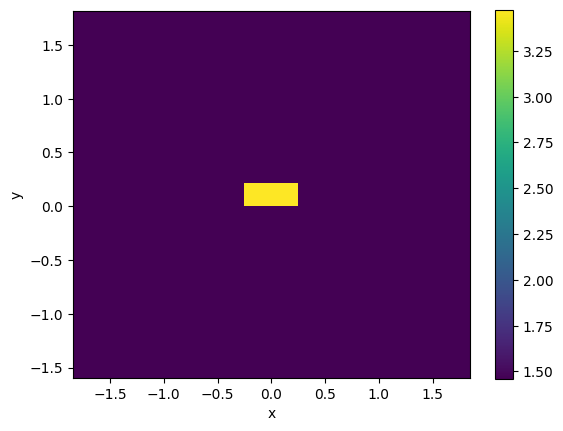

In [274]:
deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=0.5, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=1.5, # Parameters of the grid 
    grid_resolution=20, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
)

deep_waveguide.plot_index()


2026-11-09 01:52:56.740 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_898101cb83302c4e.npz.
2026-11-09 01:52:56.755 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_223d93916735b32f.npz.
2026-11-09 01:52:56.758 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_bfb11438ea20eb9b.npz.
2026-11-09 01:52:56.759 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_e57b1482e9676d81.npz.
2026-11-09 01:52:56.761 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_a44f40f4b17bc379.npz.
2026-11-09 01:52:56.763 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_ab617adb3c2a6601.npz.
2026-11-09 01:52:56.765 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_8810f2428c078017.npz.
2026-11-09 01:52:56.769 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_4181bf75add56d48.npz.


/tmp/ipykernel_231966/2705652220.py:28: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o" (-> marker='o'). The keyword argument will take precedence.
  plt.plot(gridres, realneff, 'o',marker='o', linestyle='-', markersize=8)


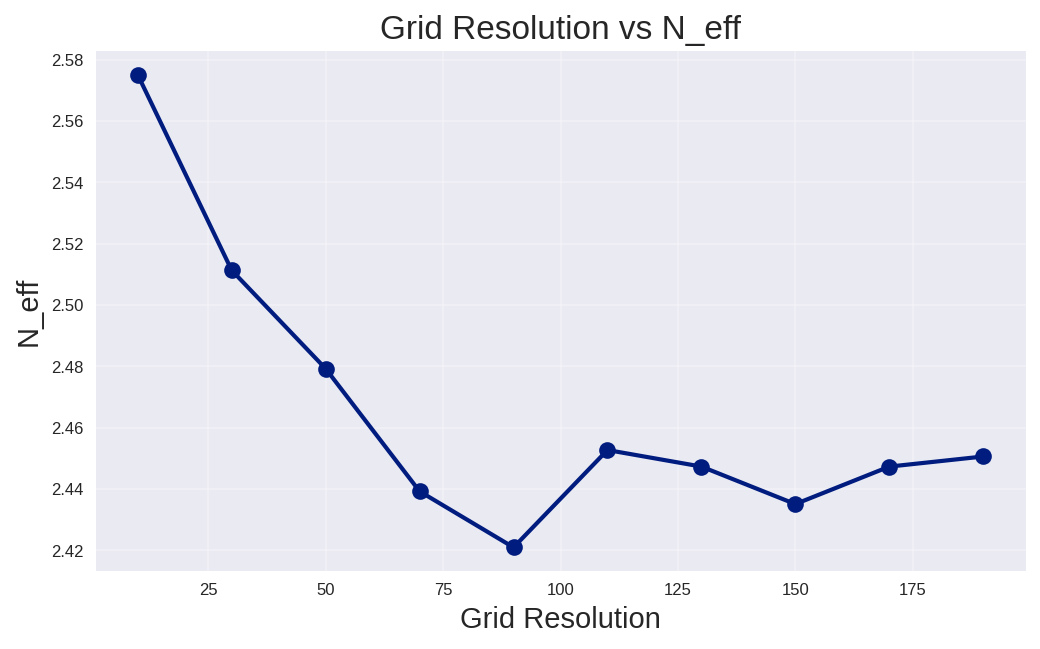

In [43]:
def get_TF00(gridres):
    deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=0.5, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=1.2, # Parameters of the grid 
    grid_resolution=gridres, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    )
    return deep_waveguide.n_eff[0]
tf00 = []
for i in range(10,110,10):
    tf00.append(get_TF00(i))
print(tf00)
#plotc
gridres=[i for i in range(10,200,20)]
realneff = [i.real for i in tf00]
print(gridres)
print(realneff)
plt.plot(gridres, realneff, 'o',marker='o', linestyle='-', markersize=8)
plt.xlabel('Grid Resolution')
plt.ylabel('N_eff')
plt.title('Grid Resolution vs N_eff')
plt.grid(True)
plt.show()

[1.2 1.3 1.4 1.5 1.6]
2026-11-09 01:53:10.236 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_8810f2428c078017.npz.
2026-11-09 01:53:10.237 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_99c25f01ccfb37c3.npz.
2026-11-09 01:53:10.255 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_13eeac5bce9b83a3.npz.
2026-11-09 01:53:10.257 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_4db3223ebb6f4d01.npz.
2026-11-09 01:53:10.259 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_c130f44ecf9bef98.npz.
[np.complex128(2.447319439913911+5.211321395369576e-05j), np.complex128(2.4471029609372255+5.215910431315683e-05j), np.complex128(2.4652887321561283+4.9880043110543215e-05j), np.complex128(2.4469667248487754+5.219056293135527e-05j), np.complex128(2.446978799780988+5.218751774535493e-05j)]


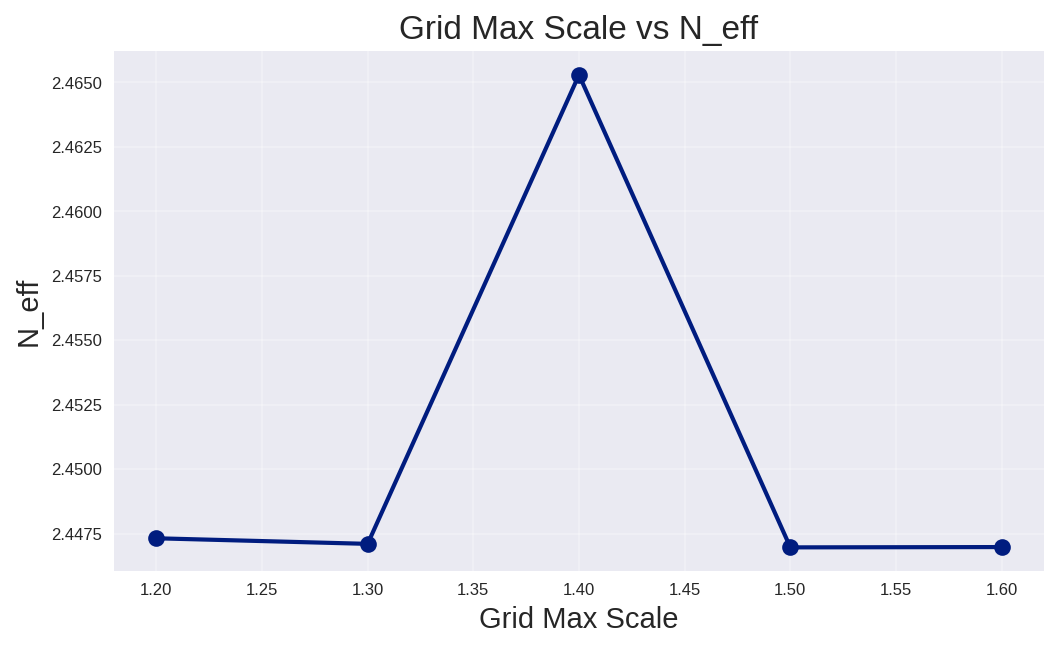

In [44]:

# 1.2 to 1.6 in 0.1
max_grid_scal = np.arange(1.2, 1.6, 0.1)
print(max_grid_scal)

def get_max_grid_scale(gridres, max_grid_scale):
    deep_waveguide = gt.modes.Waveguide(
    # Geometrical Parameters
    core_width=0.5, # Waveguide width
    core_thickness=220 * nm, # Waveguide height 
    slab_thickness=0 * nm, # For shallow waveguides - Set to 0 if its a deep-etched waveguide.
    # Materials
    core_material='si', #  Material of the waveguide
    clad_material='sio2', # Surrounding material
    # Modesolver Parameters
    wavelength=1550 * nm, # Wavelength to simulate
    num_modes=4, # Targeted number of modes to find 
    max_grid_scaling=max_grid_scale, # Parameters of the grid 
    grid_resolution=70, # Parameters of the grid
    cache_path='.cache/', # Important! In order to save simulation time, set your cache Path!
    precision='double',
    )
    return deep_waveguide.n_eff[0]
tf00_maxgrid_scale = []
for i in max_grid_scal:
    tf00_maxgrid_scale.append(get_max_grid_scale(last_grid_res, i))
print(tf00_maxgrid_scale)
#plot
x=max_grid_scal
y =  [i.real for i in tf00_maxgrid_scale]

plt.plot(x, y, marker='o', linestyle='-', markersize=8)
plt.xlabel('Grid Max Scale')
plt.ylabel('N_eff')
plt.title('Grid Max Scale vs N_eff')
#plt.hlines(np.mean(box_index), xmin=np.min(x), xmax=np.max(x), colors='k', linestyles='dashed',label='SiO2 index')

plt.grid(True)
plt.show()

# LO.2

  0%|          | 0/7 [00:00<?, ?it/s]

2026-11-09 02:02:03.768 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_c5fe9a0575bd11ba.npz.
2026-11-09 02:02:03.779 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_55523e558fa084b4.npz.
2026-11-09 02:02:03.781 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_99c25f01ccfb37c3.npz.
2026-11-09 02:02:03.782 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_7bba90417f64ddc2.npz.
2026-11-09 02:02:03.785 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_b08b2f0185d1370a.npz.
2026-11-09 02:02:03.787 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_34b25b79cc89c14d.npz.
2026-11-09 02:02:03.789 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_f1f658d9c5913440.npz.


  0%|          | 0/7 [00:00<?, ?it/s]

2026-11-09 02:02:03.799 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_c5fe9a0575bd11ba.npz.
2026-11-09 02:02:03.800 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_55523e558fa084b4.npz.
2026-11-09 02:02:03.803 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_99c25f01ccfb37c3.npz.
2026-11-09 02:02:03.805 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_7bba90417f64ddc2.npz.
2026-11-09 02:02:03.807 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_b08b2f0185d1370a.npz.
2026-11-09 02:02:03.808 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_34b25b79cc89c14d.npz.
2026-11-09 02:02:03.809 | INFO     | gplugins.tidy3d.modes:_data:266 - load data from .cache/Waveguide_f1f658d9c5913440.npz.


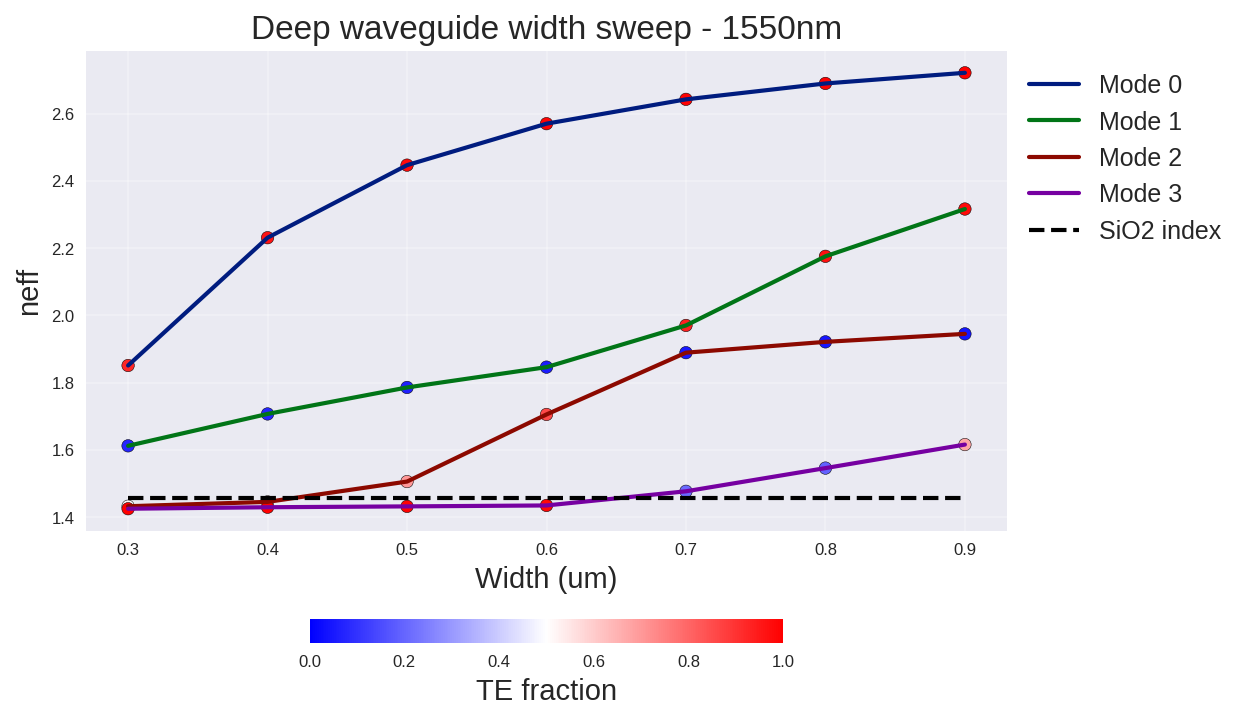

In [45]:
wavelength = 1550 * nm # Student code here

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength,
    core_width=0.5,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    slab_thickness=0 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.3,
    grid_resolution=70, 
)

w = np.arange(0.3, 1, 0.1)

sweep_neff = gt.modes.sweep_n_eff(deep_waveguide, 
                             core_width=w)

sweep_tefraction = gt.modes.sweep_fraction_te(deep_waveguide,
                                              core_width=w)

plt.figure(figsize=(10, 5))
for k in range(sweep_neff.shape[1]):
    plt.scatter(w, sweep_neff[:,k].real,edgecolors='k',c=sweep_tefraction.sel(mode_index=k),vmin=0, vmax=1,label = '__nolegend__',cmap='bwr')
    plt.plot(w, sweep_neff[:,k].real,label=f'Mode {k}')

plt.title("Deep waveguide width sweep - 1550nm")
plt.xlabel("Width (um)")
plt.ylabel("neff")
plt.grid()
plt.hlines(np.mean(box_index), xmin=np.min(w), xmax=np.max(w), colors='k', linestyles='dashed',label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.colorbar(orientation='horizontal',fraction=0.04).set_label("TE fraction")

# LO3

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

09:02:01 CET WARNING: Mode field at frequency index 0, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 1, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 2, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 3, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 4, mode index 3 does not    
             decay at the plane boundaries.                                     

... (3 outputs left out)

09:02:02 CET WARNING: Mode field at frequency index 8, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 9, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 10, mode index 3 does not   
             decay at the plane boundaries.                                     

2026-11-06 09:02:02.267 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache/Waveguide_a0313d1d5f43ad0f.npz.


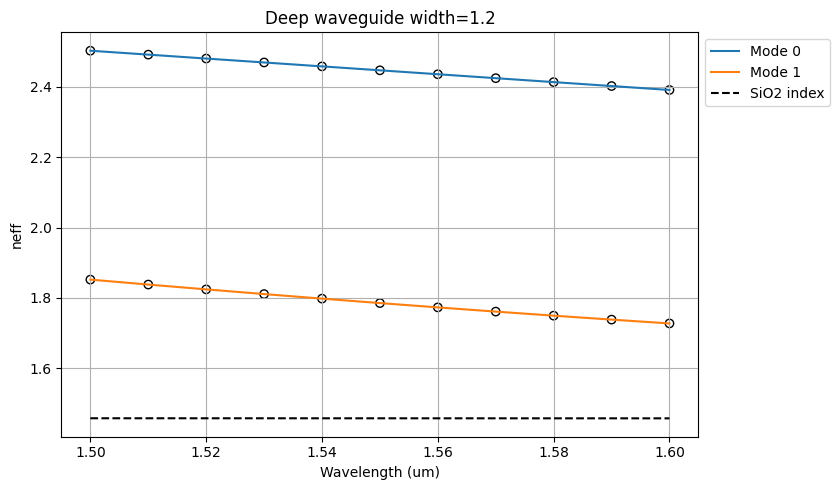

In [308]:
# STUDENT! Put your code here.

# The wavelength could be a vector also
#DEEP WG
wavelength = np.linspace(1.5,1.6,11)  # Student code here. Tip np.linspace()

deep_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=0.5, 
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=70, 
)

res_neff = deep_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = deep_waveguide.fraction_te # Wavelength-dependent vector
res_tm =deep_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))
for k in [0, 1]:
    # It's necessary to 'access' each element on the array
    plt.scatter(wavelength, res_neff[:,k].real,edgecolors='k',facecolors='none',label = '__nolegend__')
    plt.plot(wavelength, res_neff[:,k].real,label=f'Mode {k}')
plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (um)")
plt.ylabel("neff")
plt.grid()
plt.plot(wavelength, box_index,'k--', label='SiO2 index')
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout(rect=[0, 0, 0.85, 1])


#Data to fit for mode0
wavelength_dif = wavelength-1.55
neff0 = res_neff[:,0]

#Data to fit for mode1
neff1 = res_neff[:,1]


Mode 0 n1=2.4473433948888172, n2=-1.1164042027574905, n3=-0.03411368317125135
Mode 1 n1=1.785408962370002, n2=-1.2462180609843188, n3=1.7716370397496153


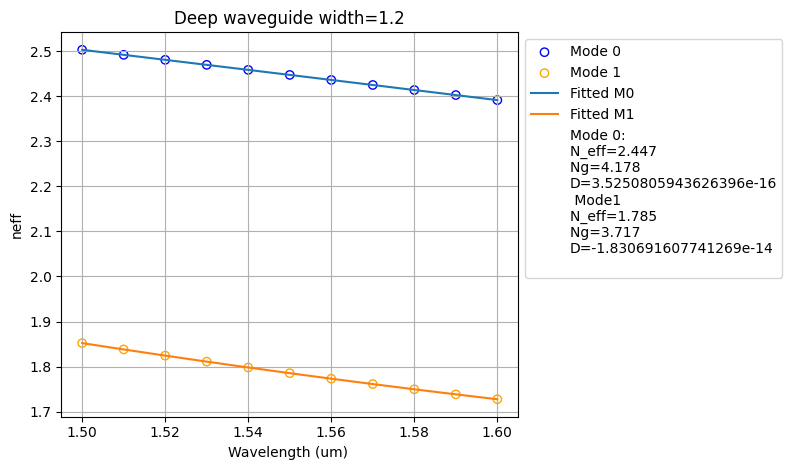

In [310]:
#deep waveguide fit
p = np.polyfit(wavelength_dif, neff0.real, 2)
p1 = np.polyfit(wavelength_dif, neff1.real, 2)
print (f"Mode 0 n1={p[-1]}, n2={p[1]}, n3={p[0]}")
print (f"Mode 1 n1={p1[-1]}, n2={p1[1]}, n3={p1[0]}")
#Mode 0
neff0_fit = np.polyval(p, wavelength_dif)
neff1_fit = np.polyval(p1, wavelength_dif)
n1 = p[-1]
ng = p[-1] - p[1]*1.55
D = -(2*1.55*1e-6*p[0]) / (3e8)
#Mode 1
neff1_fit = np.polyval(p1, wavelength_dif)
Mod1_1n1 = p1[-1]
Mod1_1ng = p1[-1] - p1[1]*1.55
Mod1_D = -(2*1.55*1e-6*p1[0]) / (3e8)

plt.scatter(wavelength, neff0.real,edgecolors='blue',facecolors='none',label = 'Mode 0')
plt.scatter(wavelength, neff1.real,edgecolors='orange',facecolors='none',label = 'Mode 1')

plt.plot(wavelength, neff0_fit, label="Fitted M0")
plt.plot(wavelength, neff1_fit, label="Fitted M1")

plt.title(f"Deep waveguide width={1.2}")
plt.xlabel("Wavelength (um) ")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.ylabel("neff")
plt.grid()
handles, labels = plt.gca().get_legend_handles_labels()
datamode0 = f"N_eff={str(p[-1])[0:5]} \nNg={ng:.3f} \nD={D}\n"
datamode1 = f"N_eff={str(Mod1_1n1)[0:5]} \nNg={Mod1_1ng:.3f} \nD={Mod1_D}\n"

handles.append(Line2D([], [], linestyle='none', label="Mode 0: \n" +datamode0+" Mode1\n"+datamode1))

plt.legend(handles=handles, loc='upper left', bbox_to_anchor=(1, 1))


/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

09:11:02 CET WARNING: Mode field at frequency index 0, mode index 2 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 0, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 1, mode index 2 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 1, mode index 3 does not    
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 2, mode index 2 does not    
             decay at the plane boundaries.                                     

... (20 outputs left out)

             WARNING: Mode field at frequency index 10, mode index 2 does not   
             decay at the plane boundaries.                                     

             WARNING: Mode field at frequency index 10, mode index 3 does not   
             decay at the plane boundaries.                                     

2026-11-06 09:11:02.944 | INFO     | gplugins.tidy3d.modes:_data:306 - store data into .cache/Waveguide_eb684b66c33d6681.npz.
Mode 0 n1=2.600642172344169, n2=-0.79409696927311, n3=0.17182977959916457
Mode 1 n1=2.2641104914834282, n2=-0.6452036546496338, n3=0.3894800414056233


<Figure size 640x480 with 0 Axes>

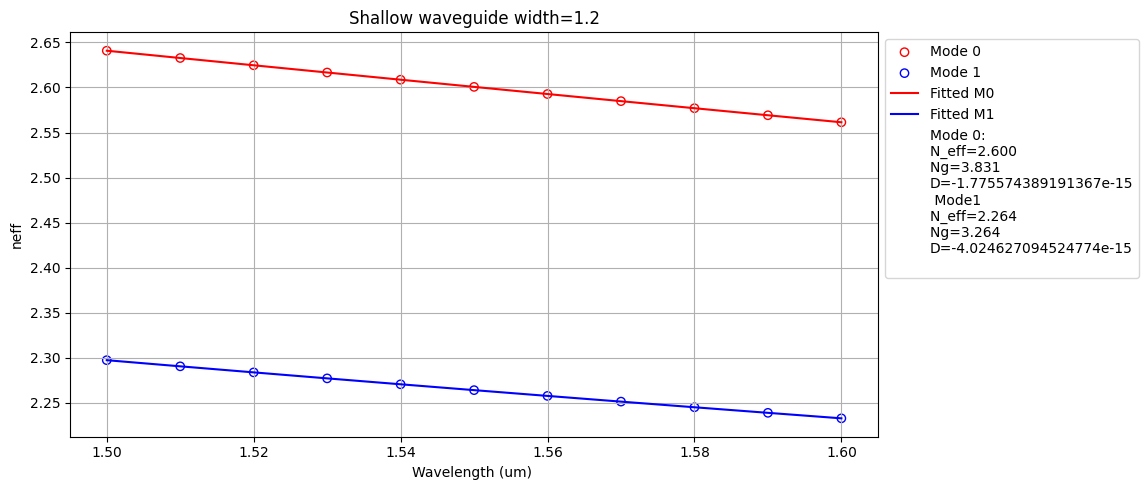

In [ ]:
# STUDENT! Put your code here. Shallow
wavelength = np.linspace(1.5,1.6,11)  # Student code here. Tip np.linspace()
plt.clf()
shallow_waveguide = gt.modes.Waveguide(
    wavelength=wavelength, 
    core_width=0.5, 
    slab_thickness=110*nm,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=4,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    grid_resolution=70, 
)

res_neff = shallow_waveguide.n_eff # In this case, the result is not just a number, is a wavelength-dependent vector
res_te = shallow_waveguide.fraction_te # Wavelength-dependent vector
res_tm =shallow_waveguide.fraction_tm # Wavelength-dependent vector

plt.figure(figsize=(10, 5))



#Data to fit for mode0
wavelength_dif = wavelength-1.55
neff0 = res_neff[:,0]

#Data to fit for mode1
neff1 = res_neff[:,1]

p = np.polyfit(wavelength_dif, neff0.real, 2)
p1 = np.polyfit(wavelength_dif, neff1.real, 2)
print (f"Mode 0 n1={p[-1]}, n2={p[1]}, n3={p[0]}")
print (f"Mode 1 n1={p1[-1]}, n2={p1[1]}, n3={p1[0]}")
#Mode 0
neff0_fit = np.polyval(p, wavelength_dif)
neff1_fit = np.polyval(p1, wavelength_dif)
n1 = p[-1]
ng = p[-1] - p[1]*1.55
D = -(2*1.55*1e-6*p[0]) / (3e8)
#Mode 1
neff1_fit = np.polyval(p1, wavelength_dif)
Mod1_1n1 = p1[-1]
Mod1_1ng = p1[-1] - p1[1]*1.55
Mod1_D = -(2*1.55*1e-6*p1[0]) / (3e8)

plt.scatter(wavelength, neff0.real,edgecolors='red',facecolors='none',label = 'Mode 0', color= "red",)
plt.scatter(wavelength, neff1.real,edgecolors='blue',facecolors='none',label = 'Mode 1', color= "blue")

plt.plot(wavelength, neff0_fit, label="Fitted M0", color= "red")
plt.plot(wavelength, neff1_fit, label="Fitted M1", color= "blue")

plt.title(f"Shallow waveguide width={1.2}")
plt.xlabel("Wavelength (um) ")
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.ylabel("neff")
plt.grid()
handles, labels = plt.gca().get_legend_handles_labels()
datamode0 = f"N_eff={str(p[-1])[0:5]} \nNg={ng:.3f} \nD={D}\n"
datamode1 = f"N_eff={str(Mod1_1n1)[0:5]} \nNg={Mod1_1ng:.3f} \nD={Mod1_D}\n"

handles.append(Line2D([], [], linestyle='none', label="Mode 0: \n" +datamode0+" Mode1\n"+datamode1))

plt.legend(handles=handles, loc='upper left', bbox_to_anchor=(1, 1))
# L4

# L4

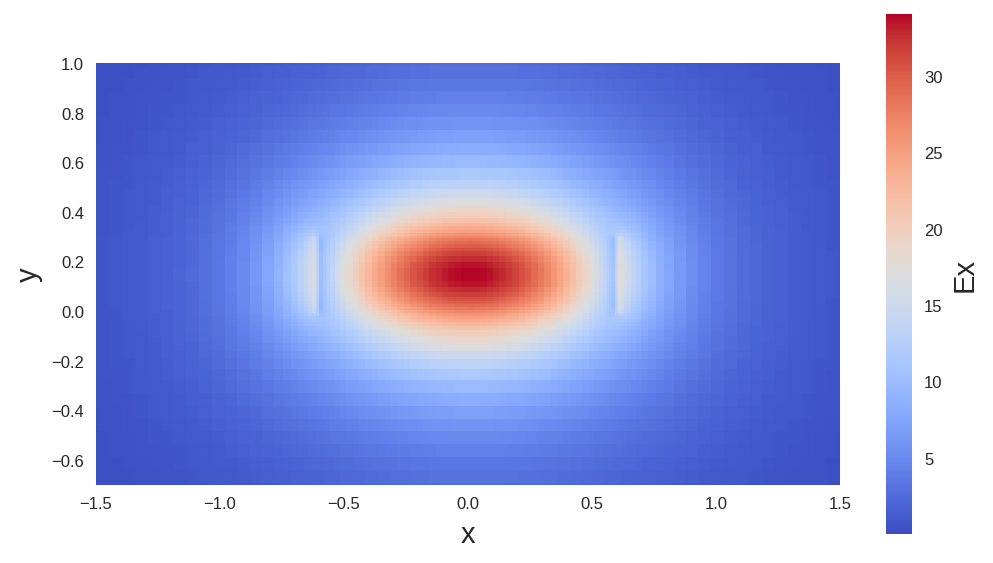

In [57]:
bend_1550_si = gt.modes.Waveguide(
    wavelength=1550 * nm,
    core_width=0.5,
    slab_thickness=0.0,
    core_material='si',
    clad_material='sio2',
    core_thickness=220 * nm,
    num_modes=1,
    cache_path='.cache/',
    precision='double',
    max_grid_scaling=1.2,
    
    grid_resolution=70, 
    bend_radius=200, # Bend radius
)

bend_1550.plot_field(field_name="Ex", 
                     mode_index=0, # Field to be plotted
                     value='abs', # Real - abs - imag
                     cmap='coolwarm',
                     xlim=(-1.5, 1.5), # Set the x and y limits
                     ylim=(-0.7, 1)) 

  0%|          | 0/6 [00:00<?, ?it/s]

/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:14: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxf = sp.csr_matrix(sp.diags([-1, 1], [0, 1], shape=(Nx, Nx)))
/home/diegod/Documents/valencia_curso/LAB1true/pic-upv-lab1/.venv/lib/python3.12/site-packages/tidy3d/components/mode/derivatives.py:27: FutureWarning: Input has data type int64, but the output has been cast to float64.  In the future, the output data type will match the input. To avoid this warning, set the `dtype` parameter to `None` to have the output dtype match the input, or set it to the desired output data type.
  dxb = sp.csr_matrix(sp.diags([1, -1], [0, -1], shape=(Nx, Nx)))
/home/diegod/Documents/

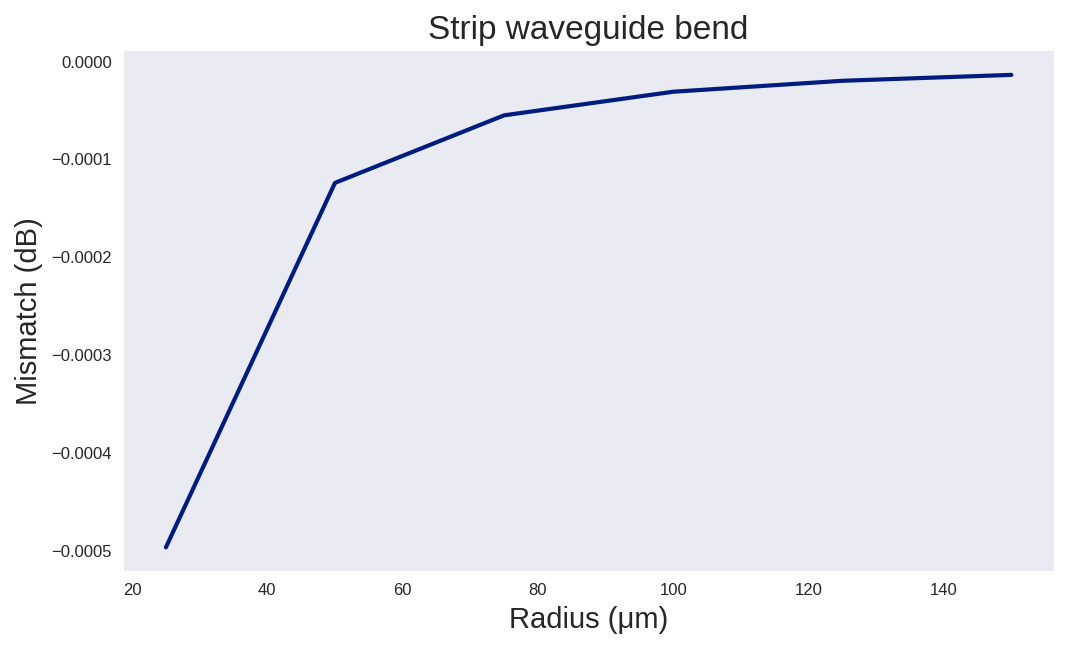

In [63]:
radii = np.arange(25.0, 175,25)

mismatch_soi = gt.modes.sweep_bend_mismatch(bend_1550_si, radii)
plt.clf()
plt.plot(radii, 10 * np.log10(mismatch_soi))
plt.title("Strip waveguide bend")
plt.xlabel("Radius (μm)")
plt.ylabel("Mismatch (dB)")
plt.show()

/tmp/ipykernel_231966/1809292075.py:7: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, -10 * np.log10(mismatch_soi), ".", label="Mode loss",marker='o', linestyle='-', markersize=5)
/tmp/ipykernel_231966/1809292075.py:8: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, propagation_loss, ".", label="Propagation loss", marker='o', linestyle='-', markersize=5)
/tmp/ipykernel_231966/1809292075.py:9: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "." (-> marker='.'). The keyword argument will take precedence.
  plt.plot(radii, propagation_loss-10 * np.log10(mismatch_soi), ".", label="Total loss", marker='o', linestyle='-', markersize=5)


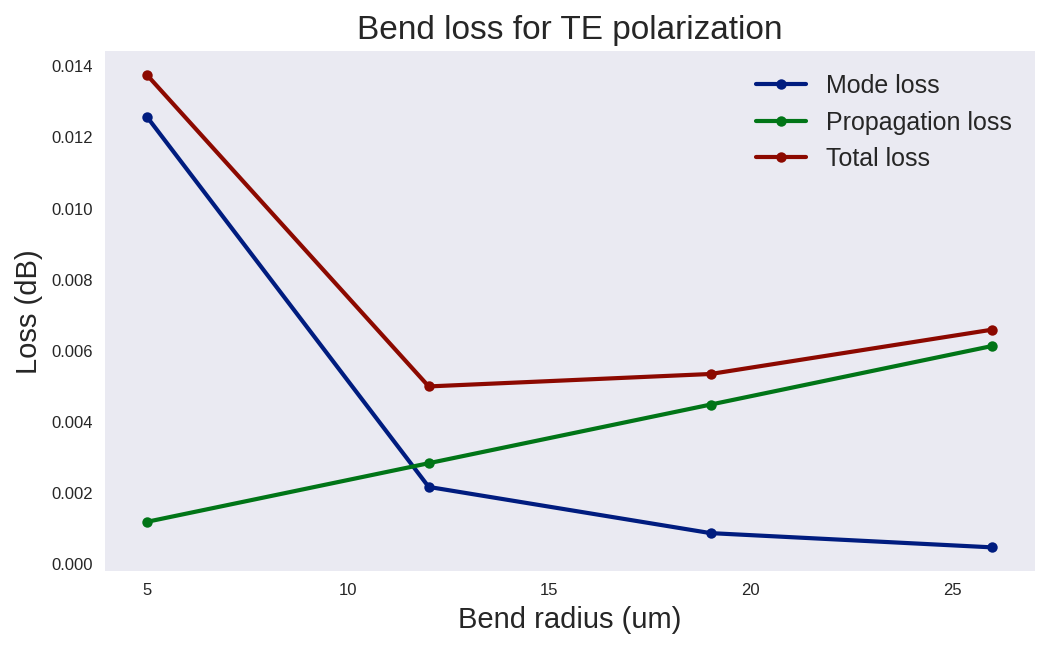

In [59]:
dB_cm = 1.5  # dB/cm Technology loss - 
length = 0.5 * np.pi * radii * 1e-6
propagation_loss = dB_cm * length * 1e2
propagation_loss
plt.clf()
plt.title("Bend loss for TE polarization")
plt.plot(radii, -10 * np.log10(mismatch_soi), ".", label="Mode loss",marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss, ".", label="Propagation loss", marker='o', linestyle='-', markersize=5)
plt.plot(radii, propagation_loss-10 * np.log10(mismatch_soi), ".", label="Total loss", marker='o', linestyle='-', markersize=5)
plt.xlabel("Bend radius (um)")
plt.ylabel("Loss (dB)")
plt.legend()

1) 
- Resolution sweep is more unstable compared to sin, it requires more resolution (20vs70)
- Requires smaller max scale (1.2), sweep resultss shows also more unstable compared to sin
- Higher processing times.
2) 
- Smaller geometry
- Higher neff due to bigger difference between the refractive index of core and cladding
- Smaller separation between modes

3) Considerable smaller bend radius

